In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


KB kanal B   : 2.04
KB kanal G   : 0.48
KB kanal R   : 8.21
KB kanal Gray: 3.87
KB kanal H   : 6.19
KB kanal S   : 1.22
KB kanal V   : 2.20


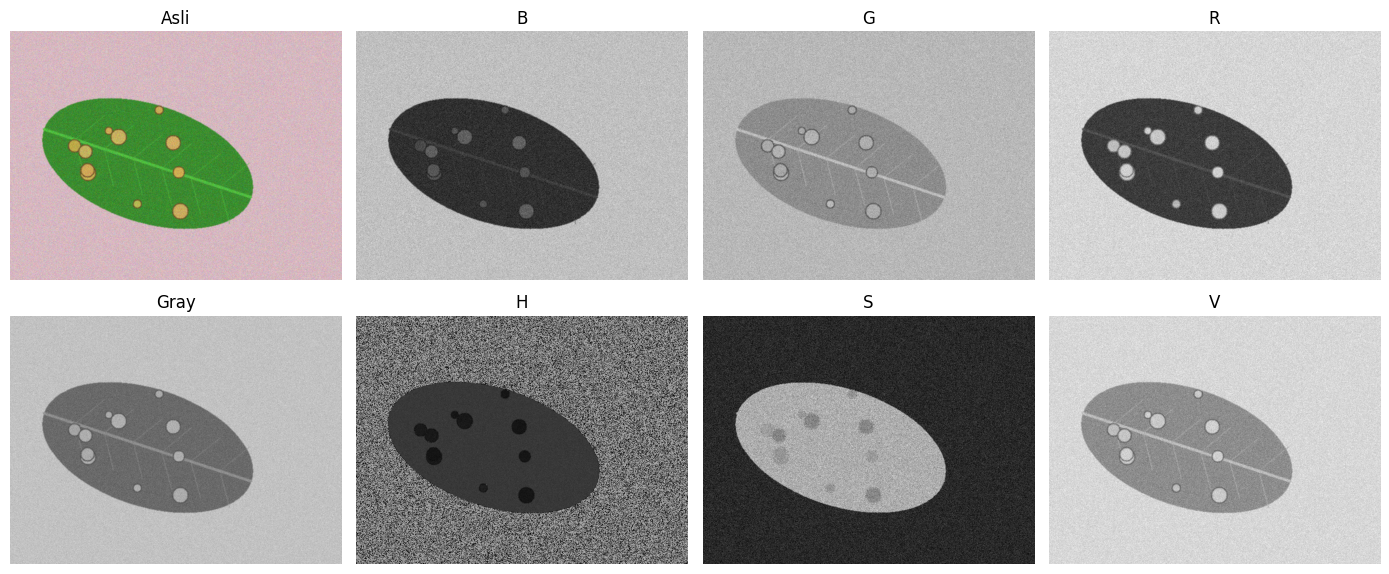

In [2]:
import sys
# Daftarkan folder src ke dalam sistem agar utils_cv terbaca
sys.path.append('/content/drive/MyDrive/simuteh-2330511092/src')

import cv2
import numpy as np
import matplotlib.pyplot as plt
from utils_cv import kontras_bercak, baca, tampil
nama = "teh_041.png" # kelas berat, kondisi normal
img = baca(f"drive/MyDrive/simuteh-2330511092/data/sintetis/citra/{nama}")
md = cv2.imread(f"drive/MyDrive/simuteh-2330511092/data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"drive/MyDrive/simuteh-2330511092/data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
 baris=2, ukuran=(14, 6))
for nm, c in kanal.items():
 print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [3]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
for fx in [0.5, 0.2, 0.1, 0.05]:
 kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
 besar = cv2.resize(kecil, gray.shape[::-1],
 interpolation=cv2.INTER_NEAREST)
 print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md,
mb):.2f}")
# kuantisasi: sisakan k bit
for k in [1, 2, 3, 4, 8]:
 langkah = 256 // (2 ** k)
 kuant = (gray // langkah) * langkah
 print(f"k={k}: {len(np.unique(kuant))} level, "
 f"KB={kontras_bercak(kuant, md, mb):.2f}")

fx=0.5: ukuran (240, 320), KB=5.01
fx=0.2: ukuran (96, 128), KB=4.72
fx=0.1: ukuran (48, 64), KB=3.44
fx=0.05: ukuran (24, 32), KB=1.85
k=1: 2 level, KB=3.40
k=2: 3 level, KB=3.44
k=3: 6 level, KB=3.28
k=4: 11 level, KB=3.57
k=8: 162 level, KB=3.87


In [5]:
import pandas as pd
def semua_kanal(img):
 hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
 b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
 return {"B": b, "G": g, "R": r,
 "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
 "H": h, "S": s, "V": v}
label = pd.read_csv("drive/MyDrive/simuteh-2330511092/data/sintetis/label.csv")
baris = []
for _, d in label[label.kelas == "berat"].iterrows():
 im = baca(f"drive/MyDrive/simuteh-2330511092/data/sintetis/citra/{d.nama_file}")
 m_d = cv2.imread(f"drive/MyDrive/simuteh-2330511092/data/sintetis/mask_daun/{d.nama_file}", 0)
 m_b = cv2.imread(f"drive/MyDrive/simuteh-2330511092/data/sintetis/mask_bercak/{d.nama_file}", 0)
 kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
 kb["kondisi"] = d.kondisi_cahaya
 baris.append(kb)
tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print(tabel_kb)
tabel_kb.to_csv("drive/MyDrive/simuteh-2330511092/hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.78  0.52   6.26  2.00  5.48  1.29  1.13
gelap           1.50  0.93  10.05  4.06  6.21  1.16  2.68
kontras_rendah  0.80  0.46   3.86  2.17  1.92  0.29  1.41
normal          2.62  1.27  10.18  5.10  7.48  1.24  3.07
terang          1.95  0.52   7.67  3.84  6.37  0.96  1.90


Rerata KB Kelas Ringan:
kanal                  B         G      Gray         H         R         S  \
kondisi                                                                      
bayangan        0.984753  0.487684  1.144729  5.180280  4.778420  0.945007   
gelap           0.764555  0.892854  2.537543  7.294719  9.346012  1.089099   
kontras_rendah  0.689064  0.561052  1.026534  2.459226  3.289787  0.664711   
normal          1.075627  0.677628  2.609263  8.396187  8.557033  1.192754   
terang          1.297796  0.549728  2.293811  4.675804  5.318432  0.765306   

kanal                  V  
kondisi                   
bayangan        0.603914  
gelap           1.524945  
kontras_rendah  0.302934  
normal          0.805776  
terang          1.004163  

Perbandingan Visual Kanal Terbaik (R dan H):


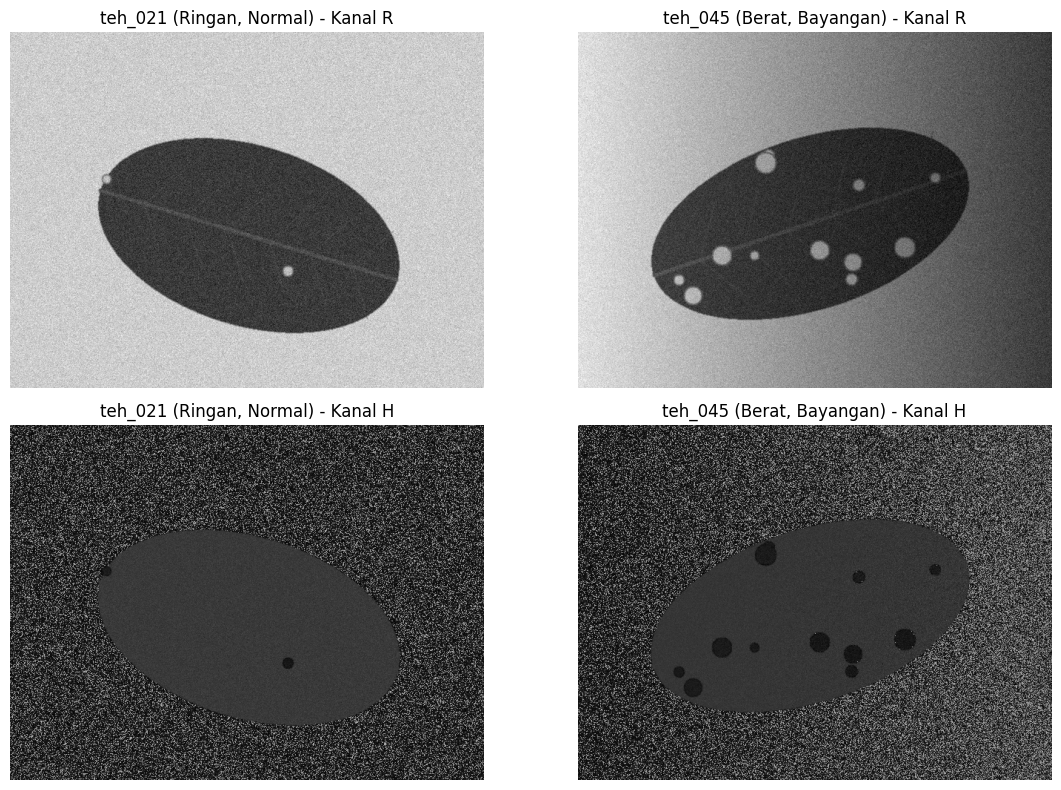

In [8]:
import cv2
import pandas as pd
from utils_cv import baca, tampil, kontras_bercak

# --- 1. Hitung Rerata KB untuk Kelas Ringan ---
hasil_ringan = []
for _, d in label[label['kelas'] == "ringan"].iterrows():
    nama_file = d['nama_file']
    kondisi = d['kondisi_cahaya'] # Menggunakan kolom yang benar

    im = baca(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/citra/{nama_file}")
    m_d = cv2.imread(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/mask_daun/{nama_file}", 0)
    m_b = cv2.imread(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/mask_bercak/{nama_file}", 0)

    kanals = semua_kanal(im)
    for nm, c in kanals.items():
        hasil_ringan.append({
            "nama_file": nama_file,
            "kondisi": kondisi,
            "kanal": nm,
            "kb": kontras_bercak(c, m_d, m_b)
        })

df_ringan = pd.DataFrame(hasil_ringan)
rerata_kb_ringan = df_ringan.pivot_table(index="kondisi", columns="kanal", values="kb", aggfunc="mean")
print("Rerata KB Kelas Ringan:")
print(rerata_kb_ringan)

# --- 2. Tampilkan Kanal Terbaik untuk teh_021 (Ringan) & teh_045 (Berat) ---
nama_citra = ["teh_021.png", "teh_045.png"]
judul_citra = ["teh_021 (Ringan, Normal)", "teh_045 (Berat, Bayangan)"]

citra_R = []
citra_H = []

for nama in nama_citra:
    im = baca(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/citra/{nama}")
    b, g, r = cv2.split(im)
    hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    citra_R.append(r)
    citra_H.append(h)

# Tampilkan berdampingan: Asli R vs Asli H
print("\nPerbandingan Visual Kanal Terbaik (R dan H):")
tampil(citra_R + citra_H,
       [f"{j} - Kanal R" for j in judul_citra] + [f"{j} - Kanal H" for j in judul_citra],
       baris=2, ukuran=(12, 8))

Berdasarkan hasil rata-rata nilai Kontras Bercak (KB), kanal Merah (R) dan kanal Hue (H) konsisten menjadi kanal paling unggul pada kelas infeksi berat. Saat diuji pada kelas infeksi ringan, kanal R dan H juga tetap memberikan nilai kontras tertinggi dibandingkan kanal lainnya, sehingga sangat mumpuni menonjolkan bercak kecil yang belum parah pada berbagai kondisi cahaya.

In [9]:
%cd /content/drive/MyDrive/simuteh-2330511092

/content/drive/MyDrive/simuteh-2330511092


In [10]:
!git config --global user.email "gentaaditya18@gmail.com"
!git config --global user.name "Adityagenta"

In [ ]:
!git add .